# Chapter 1 · Images as arrays

*Book 27 · Deep Learning on Images & Signals · Shelf VII*

**Builds on:** NumPy arrays and broadcasting (book 6) and vectors (book 1).
**You will:** take an image apart into numbers -- shape, channels, data type -- turn colour into
grey the way the eye does, resize without aliasing, and measure what JPEG compression costs.

Every method in this book, from a blur filter to a convolutional network, does arithmetic on a
grid of numbers. Seeing an image as that grid is the first step.

In [1]:
import io

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

from ds_toolbox import qrbills as qb
from ds_toolbox import viz

viz.use_style()

## The object of this book

The book works on one kind of image throughout: the payment part of a Swiss QR bill. The
toolbox invents bills that pass a bank's checks but belong to no one, and draws them at 150 dpi.

<class 'numpy.ndarray'> uint8 (620, 1240, 3)


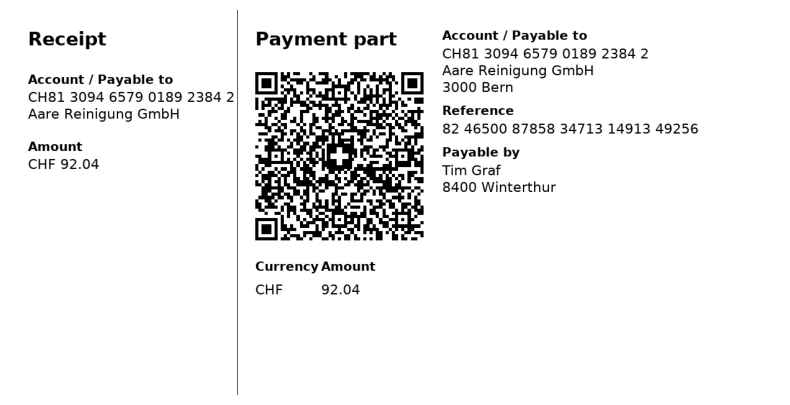

In [2]:
bill = qb.generate_bills(1, seed=1)[0]
img = qb.render(bill)
plt.figure(figsize=(10, 5))
plt.imshow(img)
plt.axis("off")
print(type(img), img.dtype, img.shape)

`(620, 1240, 3)`: 620 rows, 1240 columns, 3 channels (red, green, blue), each an integer from 0
to 255. Rows come first -- `img[y, x]`, the reverse of how we name a point on a plot.

In [3]:
dark = np.argwhere(img.sum(axis=2) == 0)[0]
print("top-left pixel:", img[0, 0], "(paper) | first black pixel at row, column", dark, "->", img[tuple(dark)])
print("bytes in memory:", img.nbytes, f"= {img.nbytes / 1e6:.1f} MB")

top-left pixel: [255 255 255] (paper) | first black pixel at row, column [  0 366] -> [0 0 0]
bytes in memory: 2306400 = 2.3 MB


## Crops are slices

A region of an image is a slice of the array -- no copying, no special API.

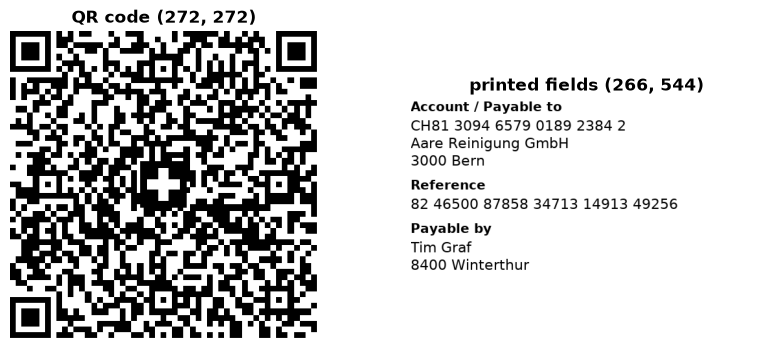

In [4]:
mm = 150 / 25.4
qr_region = img[int(17 * mm):int(63 * mm), int(67 * mm):int(113 * mm)]
text_region = img[int(5 * mm):int(50 * mm), int(118 * mm):]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(qr_region)
axes[0].set_title(f"QR code {qr_region.shape[:2]}")
axes[1].imshow(text_region)
axes[1].set_title(f"printed fields {text_region.shape[:2]}")
for a in axes:
    a.axis("off")

## From colour to grey

Most of this book's methods work on one channel. Averaging R, G and B is the obvious way and
the wrong one: the eye is far more sensitive to green than to blue. The ITU-R BT.601 weights
are what OpenCV and PIL use.

In [5]:
weights = np.array([0.299, 0.587, 0.114])
grey = img @ weights                      # a matrix-vector product per pixel
naive = img.mean(axis=2)
swatch = np.array([[[255, 0, 0], [0, 255, 0], [0, 0, 255]]], dtype=np.uint8)
print("pure red, green, blue as grey (BT.601):", (swatch @ weights).round(0))
print("the same, averaged:                   ", swatch.mean(axis=2).round(0))
print("PIL agrees with the weights to within", np.abs(np.asarray(Image.fromarray(img).convert("L"), float)
                                                     - grey).max().round(1), "grey levels")

pure red, green, blue as grey (BT.601): [[ 76. 150.  29.]]
the same, averaged:                    [[85. 85. 85.]]
PIL agrees with the weights to within 0.0 grey levels


## A histogram is the first look

A printed document is mostly white with some black: two peaks. That shape is what thresholding
(chapter 2) will exploit.

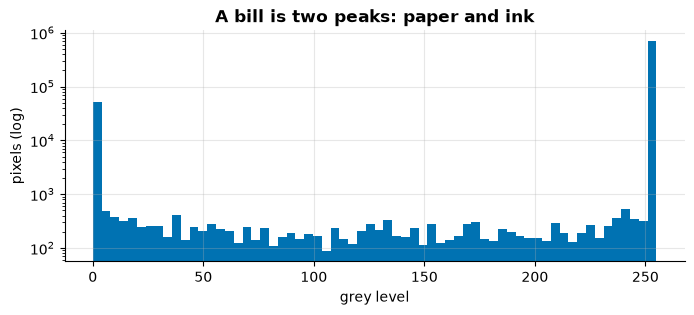

In [6]:
plt.figure(figsize=(8, 3))
plt.hist(grey.ravel(), bins=64, color=viz.PALETTE[0])
plt.yscale("log")
plt.xlabel("grey level")
plt.ylabel("pixels (log)")
plt.title("A bill is two peaks: paper and ink");

## Resizing and aliasing

Shrinking by keeping every fourth pixel (*decimation*) throws information away unevenly: thin
lines vanish or turn into patterns. Averaging over the pixels first (*area interpolation*) is
the fix -- the image version of filtering before sampling.

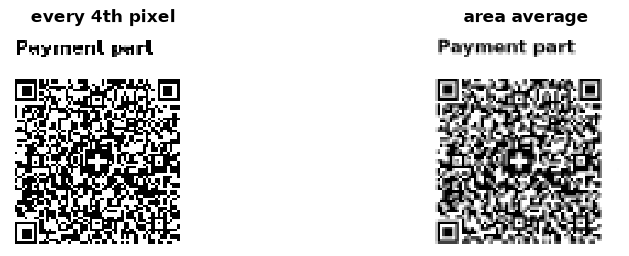

In [7]:
small_nearest = img[::4, ::4]
small_area = np.asarray(Image.fromarray(img).resize((img.shape[1] // 4, img.shape[0] // 4), Image.BOX))
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8))
for ax, im, title in zip(axes, [small_nearest, small_area], ["every 4th pixel", "area average"], strict=True):
    ax.imshow(im[int(4 * mm / 4):int(64 * mm / 4), int(66 * mm / 4):int(118 * mm / 4)], interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")

## What JPEG costs

JPEG throws away detail the eye barely sees, in 8 x 8 blocks. The quality setting trades bytes
against error. **PSNR** (peak signal-to-noise ratio) measures the error in decibels:

$$\mathrm{PSNR} = 10 \log_{10} \frac{255^2}{\mathrm{MSE}}$$

Above about 40 dB the difference is hard to see; below 30 it is obvious.

In [8]:
def psnr(a, b):
    mse = np.mean((a.astype(float) - b.astype(float)) ** 2)
    return 10 * np.log10(255 ** 2 / mse)

rows = []
for q in (95, 75, 50, 25, 10):
    buf = io.BytesIO()
    Image.fromarray(img).save(buf, format="JPEG", quality=q)
    back = np.asarray(Image.open(io.BytesIO(buf.getvalue())))
    rows.append((q, buf.tell() / 1024, psnr(img, back)))
raw_kb = img.nbytes / 1024
for q, kb, p in rows:
    print(f"quality {q:3d}: {kb:6.0f} KB ({raw_kb / kb:4.0f}x smaller), PSNR {p:5.1f} dB")

quality  95:    140 KB (  16x smaller), PSNR  53.0 dB
quality  75:     81 KB (  28x smaller), PSNR  39.5 dB
quality  50:     63 KB (  36x smaller), PSNR  35.1 dB
quality  25:     48 KB (  47x smaller), PSNR  31.2 dB
quality  10:     34 KB (  66x smaller), PSNR  27.2 dB


## What to remember

- An image is an array `[row, column, channel]` of integers; a crop is a slice.
- Grey is a weighted sum of the channels, weighted the way the eye sees.
- Average before you shrink. Measure compression with PSNR, not by eye alone.

## Exercises

1. Convert `img` to `float` in [0, 1] and back. What goes wrong if you forget to clip?
2. Find the darkest 1 % of pixels. Where on the bill are they?
3. Plot PSNR against file size for qualities 5 to 95 in steps of 5. Where is the knee?

**Next:** [Chapter 2 · Classical image processing](02-classical-image-processing.ipynb)